# CWRU dataset — a lab motor bearing

This is the other public sensor set for the benchmark. It is not a wind turbine. A motor was run on a bench at Case Western Reserve University, and accelerometers recorded the vibration. Small pits were cut into real bearings. The waveform was measured, not generated by a computer.

The slice here is enough to see the signal before any training. Four healthy recordings, then inner-race, ball, and outer-race faults at 0.007 inch and 0.021 inch, at no load and at 3 HP. Two extra outer-race files show the pit sitting beside the load or opposite it. The full 12 kHz drive-end set is larger than this slice. Training can use more of it later.

Bearing Data Center, Case Western Reserve University. The files are the official MATLAB downloads.


In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import hilbert

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

from cwru import RECORDS, fault_orders, load_recording
from signals import spectrum

rows = [load_recording(record) for record in RECORDS]
print(f"{len(rows)} recordings")
print(f"fault sample rate {rows[4]['fs']} Hz, healthy sample rate {rows[0]['fs']} Hz")


18 recordings
fault sample rate 12000 Hz, healthy sample rate 48000 Hz


## What one file holds

Each file is one run at one speed. The drive-end accelerometer is the trace this benchmark will use. A fan-end accelerometer is always present. Fault files also have a base accelerometer. The shaft speed is one number for the whole file, not a column that changes through the record.

The fault files are the 12 kHz experiment: about 122,000 samples, which is about 10 seconds. The four healthy files are the normal baseline, sampled at 48 kHz. Files 98, 99, and 100 have about 485,000 samples, again about 10 seconds. File 97 is half of that, about 5 seconds. The file does not name the unit. Healthy values sit near 0.07. A large outer-race fault reaches about 6.7.

Two healthy files, 98 and 99, do not store the speed. The table value from the data center is used there. File 99 also contains a copy of file 98. The loader keeps the arrays that belong to 99.


In [2]:
example = rows[4]
healthy = rows[0]
print(
    f"{example['name']}: drive {example['drive'].size}, "
    f"fan {example['fan'].size}, "
    f"base {None if example['base'] is None else example['base'].size}, "
    f"rpm {example['rpm']:.0f} from the {example['rpm_source']}"
)
print(
    f"{healthy['name']}: drive {healthy['drive'].size}, "
    f"base {'absent' if healthy['base'] is None else healthy['base'].size}, "
    f"{healthy['drive'].size / healthy['fs']:.1f} s at {healthy['fs']} Hz"
)
missing_speed = [row['name'] for row in rows if row['rpm_source'] == 'table']
print("speed taken from the data-center table:", ", ".join(missing_speed))


IR007_0: drive 121265, fan 121265, base 121265, rpm 1797 from the file
Normal_0: drive 243938, base absent, 5.1 s at 48000 Hz
speed taken from the data-center table: Normal_1, Normal_2


## The eighteen recordings

**rms** is the usual size of the trace. **peak** is the hardest sample. **kurt** near 3 is a steady wiggle. A higher kurtosis is a sharp hit. A healthy recording stays near 3. An outer-race pit in the load zone does not.


In [3]:
print(f"{'name':<12} {'fault':<10} {'in':>6} {'HP':>3} {'rpm':>6} {'rate':>6} {'sec':>6} {'rms':>6} {'peak':>6} {'kurt':>6}")
for row in rows:
    x = row["drive"]
    centred = x - x.mean()
    scale = centred.std()
    kurt = float(np.mean((centred / scale) ** 4))
    print(
        f"{row['name']:<12} {row['fault']:<10} {row['diameter_in']:6.3f} {row['load_hp']:3d} "
        f"{row['rpm']:6.0f} {row['fs']:6d} {x.size / row['fs']:6.1f} "
        f"{scale:6.3f} {np.max(np.abs(x)):6.3f} {kurt:6.1f}"
    )


name         fault          in  HP    rpm   rate    sec    rms   peak   kurt
Normal_0     normal      0.000   0   1796  48000    5.1  0.073  0.311    2.8
Normal_1     normal      0.000   1   1772  48000   10.1  0.065  0.346    2.9
Normal_2     normal      0.000   2   1750  48000   10.1  0.063  0.359    2.9
Normal_3     normal      0.000   3   1725  48000   10.1  0.065  0.306    3.0
IR007_0      inner       0.007   0   1797  12000   10.1  0.291  1.739    5.4
IR007_3      inner       0.007   3   1721  12000   10.2  0.314  1.671    5.3
B007_0       ball        0.007   0   1796  12000   10.2  0.139  0.607    3.0
B007_3       ball        0.007   3   1722  12000   10.1  0.154  0.721    2.9
OR007@6_0    outer_6     0.007   0   1796  12000   10.2  0.669  3.630    7.6
OR007@6_3    outer_6     0.007   3   1725  12000   10.2  0.580  3.236    8.0
OR007@3_0    outer_3     0.007   0   1797  12000   10.2  0.769  3.349    4.2
OR007@12_0   outer_12    0.007   0   1797  12000   10.2  0.237  1.763    8.1

## The waveform

The same 0.08 s from four no-load recordings. Healthy is a small steady shake. The inner-race pit repeats a clear hit. The small ball pit is only a little larger than healthy. The outer-race pit, sitting in the load zone, is a much harder hit. A 0.021 inch outer-race pit reaches about 6.7, roughly twenty times the healthy peak.


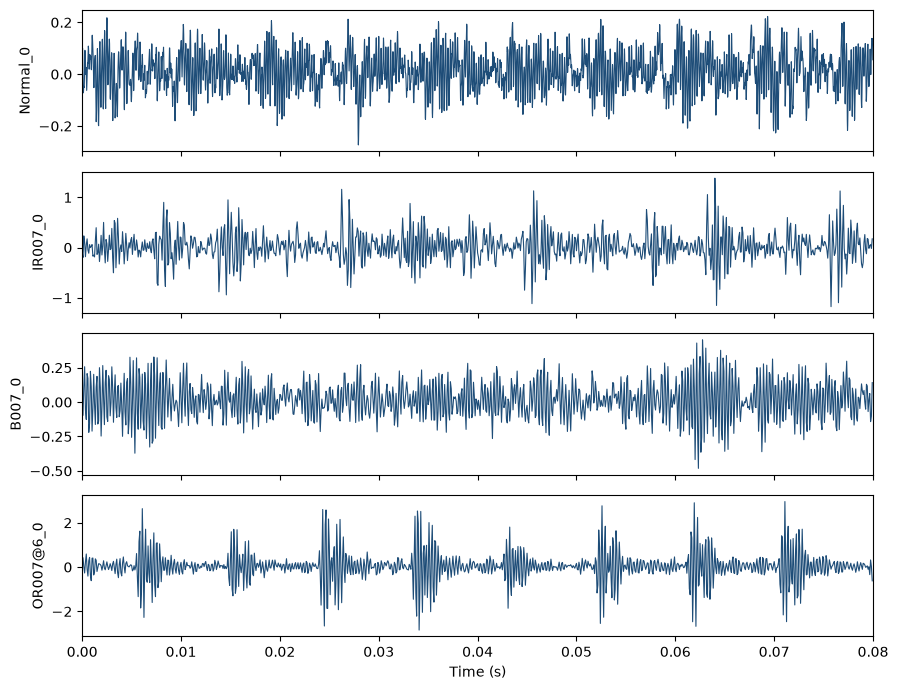

In [4]:
shown = ["Normal_0", "IR007_0", "B007_0", "OR007@6_0"]
fig, axes = plt.subplots(len(shown), 1, figsize=(9, 7), sharex=True)
for ax, name in zip(axes, shown):
    row = next(item for item in rows if item["name"] == name)
    n = int(0.08 * row["fs"])
    t = np.arange(n) / row["fs"]
    ax.plot(t, row["drive"][:n], color="#1e4d78", linewidth=0.8)
    ax.set_ylabel(name)
    ax.set_xlim(0, 0.08)
axes[-1].set_xlabel("Time (s)")
fig.tight_layout()
plt.show()


## Where the hit repeats

The drive-end bearing is an SKF 6205. Nine balls. The inner-race hit is about 5.42 times the shaft speed, and the outer-race hit is about 3.58 times. The plot is the spectrum of the signal envelope over the first two seconds. The marker is that expected rate.

On the inner-race and outer-race files, the loudest line lands on the marker. The small ball fault does not. Its trace also has kurtosis near 3, so a compressor can look accurate on it while missing a fault that is hard to see in the first place.


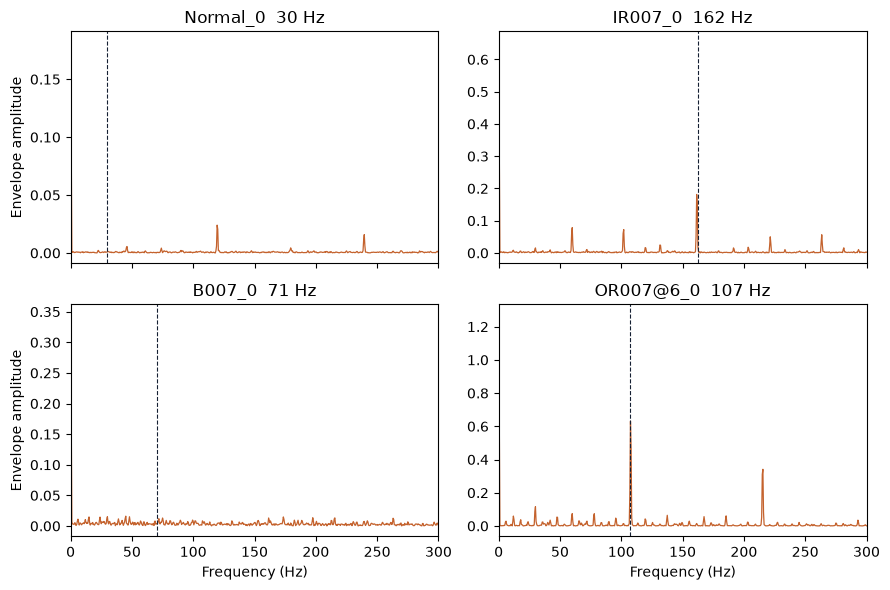

orders: inner 5.42, outer 3.58, ball 2.36


In [5]:
orders = fault_orders()
marked = [
    ("Normal_0", None),
    ("IR007_0", "inner"),
    ("B007_0", "ball"),
    ("OR007@6_0", "outer"),
]
fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=True)
for ax, (name, kind) in zip(axes.ravel(), marked):
    row = next(item for item in rows if item["name"] == name)
    n = int(2 * row["fs"])
    x = row["drive"][:n]
    envelope = np.abs(hilbert(x - x.mean()))
    freq, amp = spectrum(envelope, row["fs"])
    band = (freq >= 0) & (freq <= 300)
    ax.plot(freq[band], amp[band], color="#c4622d", linewidth=0.9)
    shaft = row["rpm"] / 60
    target = shaft if kind is None else orders[kind] * shaft
    ax.axvline(target, color="#152033", linewidth=0.8, linestyle="--")
    ax.set_title(f"{name}  {target:.0f} Hz")
    ax.set_xlim(0, 300)
for ax in axes[:, 0]:
    ax.set_ylabel("Envelope amplitude")
for ax in axes[1, :]:
    ax.set_xlabel("Frequency (Hz)")
fig.tight_layout()
plt.show()
print(
    "orders:",
    f"inner {orders['inner']:.2f}, outer {orders['outer']:.2f}, ball {orders['ball']:.2f}",
)


## What changes for the compressor

The turbine recording carries a gear tone near shaft order 35, and the speed changes from visit to visit. This motor does not. The speed is one number near 1,720–1,800 RPM, and the repeating event is the bearing pit, a few times per revolution.

A later split has to keep each file whole. Cutting one file into blocks and putting some blocks in training would leak the same run into the test. Healthy and fault files also cannot be mixed until the healthy traces are resampled from 48 kHz to 12 kHz.

The next experiment is the same comparison as on the turbine: file size, how much of the recording comes back, and the time to encode and decode, against Rice and zlib. The order-35 tone belongs to the turbine gearbox, so it is not copied onto this motor.


## One turn, then the next eight

On the slow files one shaft turn is just under 420 samples, about 35 ms. Each window is 420 samples, and the next window starts one turn later, so the two share two or three samples.

Normal_3 is healthy. OR021@6_3 is a 0.021 inch outer-race fault. Both run near 1,720 rpm, so 420 samples covers one full turn. The healthy trace is the resampled 12 kHz version.

The first row is the opening turn drawn on top of the eight turns after it. The matrix is the correlation of those nine windows. The lag plot is the same comparison over the whole file: the mean correlation of every turn with the turn 1 to 8 places later. The last figure follows RMS, peak, kurtosis, and the outer-race envelope line from one turn to the next. Kurtosis near 3 is a smooth window. A sharp hit pushes it up. The envelope line is one coarse bin, about 29 Hz wide, because a 420-sample window cannot resolve a narrower band.


Normal_3: 1725 rpm, one turn 417.4 samples, overlap 2.6 samples, 290 turns
  first turn vs the next 8: +0.05 +0.06 -0.39 +0.35 -0.01 +0.27 -0.18 -0.01
  mean over the file:        -0.08 +0.09 -0.29 +0.21 +0.02 +0.19 -0.15 -0.03
OR021@6_3: 1721 rpm, one turn 418.4 samples, overlap 1.6 samples, 291 turns
  first turn vs the next 8: +0.03 +0.30 -0.21 -0.02 -0.16 +0.01 +0.08 +0.04
  mean over the file:        -0.00 +0.08 -0.04 -0.01 -0.29 -0.01 -0.02 -0.03


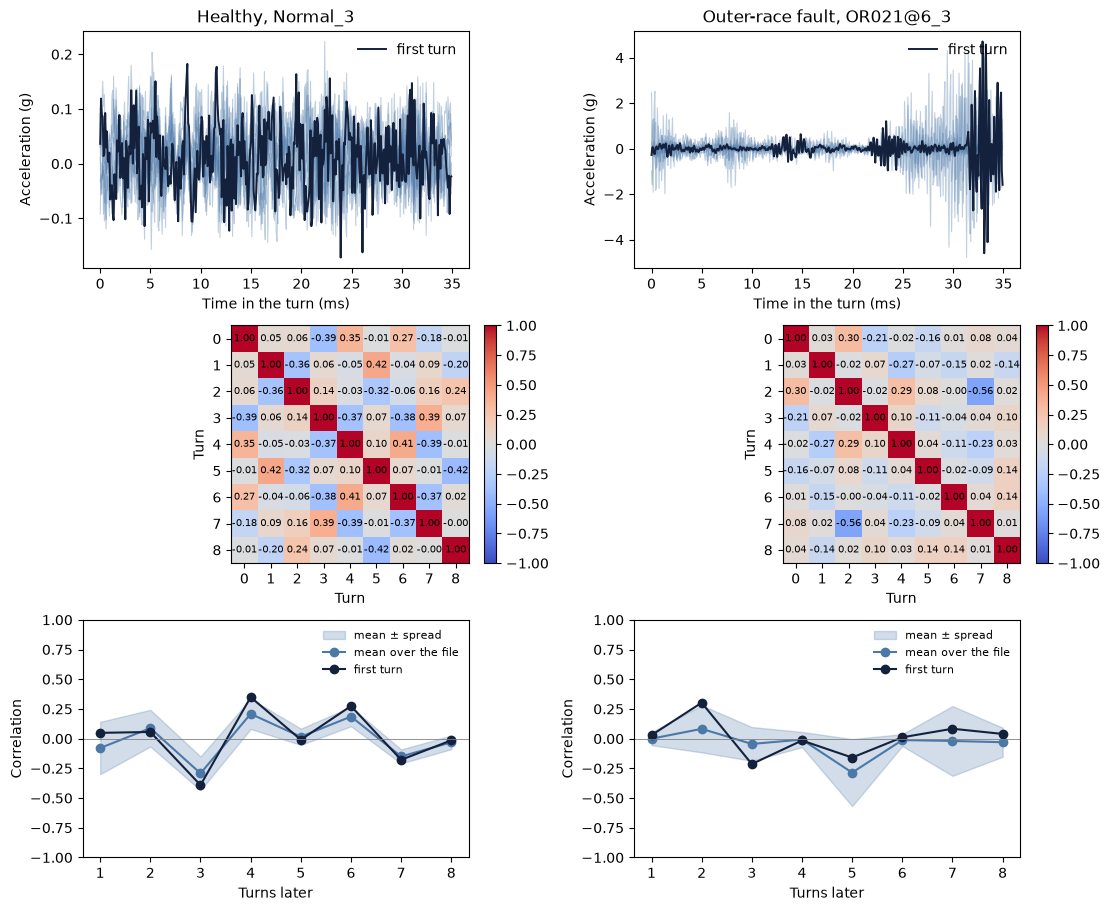

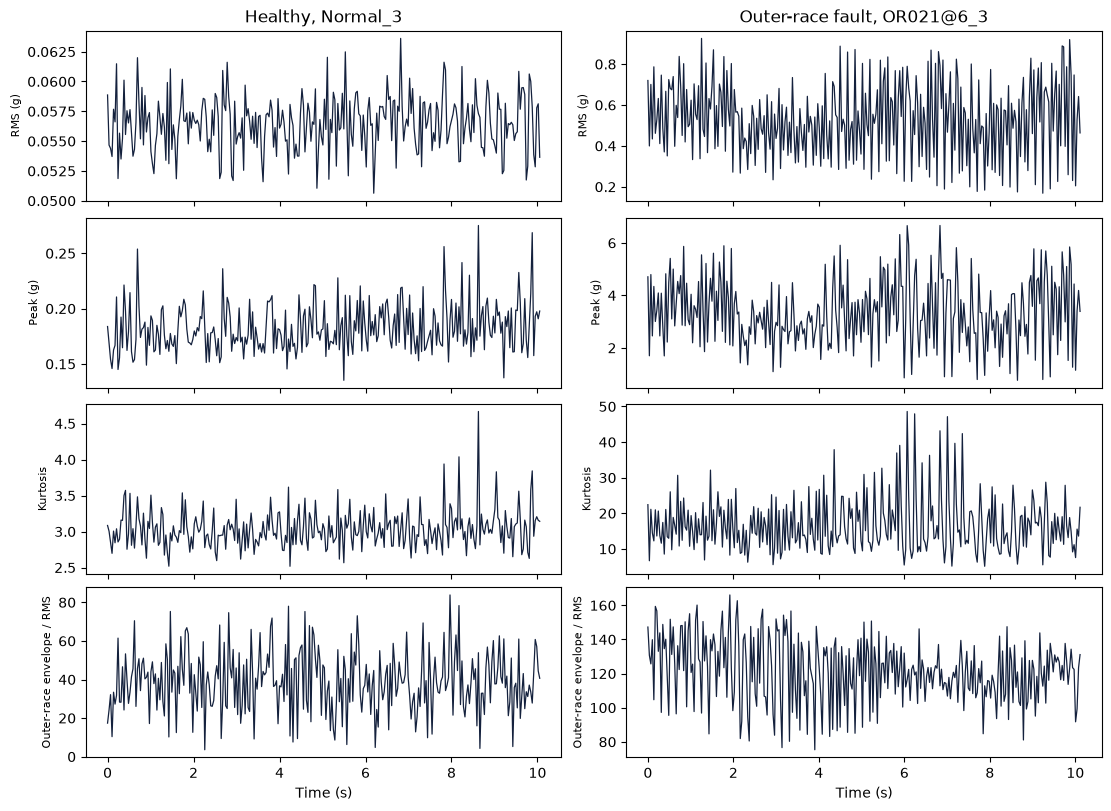

In [6]:
from scipy.signal import hilbert, resample

FS = 12_000
WINDOW = 420
NEXT = 8
PICKS = ("Normal_3", "OR021@6_3")
TITLES = {"Normal_3": "Healthy, Normal_3", "OR021@6_3": "Outer-race fault, OR021@6_3"}


def at_12khz(row):
    samples = np.asarray(row["drive"], dtype=np.float64)
    if int(row["fs"]) == FS:
        return samples
    target = int(np.round(samples.size * FS / row["fs"]))
    return resample(samples, target)


def turn_starts(n_samples, rpm):
    period = FS * 60.0 / rpm
    starts = []
    index = 0
    while True:
        start = int(np.round(index * period))
        if start + WINDOW > n_samples:
            break
        starts.append(start)
        index += 1
    return period, np.asarray(starts, dtype=int)


def correlation(left, right):
    left = left - left.mean(axis=-1, keepdims=True)
    right = right - right.mean(axis=-1, keepdims=True)
    denom = np.linalg.norm(left, axis=-1) * np.linalg.norm(right, axis=-1)
    return np.sum(left * right, axis=-1) / denom


def window_features(window, rpm):
    centred = window - float(window.mean())
    rms = float(np.sqrt(np.mean(centred ** 2)))
    peak = float(np.max(np.abs(centred)))
    kurtosis = float(np.mean((centred / max(rms, 1e-12)) ** 4))
    envelope = np.abs(hilbert(centred))
    envelope = envelope - float(envelope.mean())
    spectrum = np.abs(np.fft.rfft(envelope))
    freqs = np.fft.rfftfreq(envelope.size, d=1.0 / FS)
    center = fault_orders()["outer"] * rpm / 60.0
    outer = float(spectrum[int(np.argmin(np.abs(freqs - center)))]) / rms
    return rms, peak, kurtosis, outer


by_name = {row["name"]: row for row in rows}
chosen = []
for name in PICKS:
    row = by_name[name]
    samples = at_12khz(row)
    period, starts = turn_starts(samples.size, float(row["rpm"]))
    block = np.stack([samples[start:start + WINDOW] for start in starts])
    lag_mean = np.empty(NEXT)
    lag_std = np.empty(NEXT)
    for lag in range(1, NEXT + 1):
        values = correlation(block[:-lag], block[lag:])
        lag_mean[lag - 1] = values.mean()
        lag_std[lag - 1] = values.std()
    features = np.array([window_features(window, float(row["rpm"])) for window in block])
    chosen.append(
        {
            "name": name,
            "rpm": float(row["rpm"]),
            "period": period,
            "starts": starts,
            "block": block,
            "matrix": np.corrcoef(block[: NEXT + 1]),
            "opening": correlation(block[0:1], block[1:NEXT + 1]),
            "lag_mean": lag_mean,
            "lag_std": lag_std,
            "features": features,
        }
    )
    print(
        f"{name}: {row['rpm']:.0f} rpm, one turn {period:.1f} samples, "
        f"overlap {WINDOW - period:.1f} samples, {len(starts)} turns"
    )
    print("  first turn vs the next 8:", " ".join(f"{value:+.2f}" for value in chosen[-1]["opening"]))
    print("  mean over the file:       ", " ".join(f"{value:+.2f}" for value in lag_mean))

time_ms = np.arange(WINDOW) / FS * 1e3
lags = np.arange(1, NEXT + 1)

figure, axes = plt.subplots(3, 2, figsize=(11, 9), constrained_layout=True)
for column, item in enumerate(chosen):
    wave = axes[0, column]
    for turn in item["block"][1:NEXT + 1]:
        wave.plot(time_ms, turn, color="#4c78a8", alpha=0.35, lw=0.8)
    wave.plot(time_ms, item["block"][0], color="#14213d", lw=1.4, label="first turn")
    wave.set_title(TITLES[item["name"]])
    wave.set_xlabel("Time in the turn (ms)")
    wave.set_ylabel("Acceleration (g)")
    wave.legend(frameon=False, loc="upper right")

    grid = axes[1, column]
    image = grid.imshow(item["matrix"], vmin=-1, vmax=1, cmap="coolwarm")
    grid.set_xticks(range(NEXT + 1), [str(turn) for turn in range(NEXT + 1)])
    grid.set_yticks(range(NEXT + 1), [str(turn) for turn in range(NEXT + 1)])
    grid.set_xlabel("Turn")
    grid.set_ylabel("Turn")
    for row_index in range(NEXT + 1):
        for col_index in range(NEXT + 1):
            grid.text(
                col_index,
                row_index,
                f"{item['matrix'][row_index, col_index]:.2f}",
                ha="center",
                va="center",
                fontsize=7,
                color="black",
            )
    figure.colorbar(image, ax=grid, fraction=0.046, pad=0.04)

    lag_axis = axes[2, column]
    lag_axis.fill_between(
        lags,
        item["lag_mean"] - item["lag_std"],
        item["lag_mean"] + item["lag_std"],
        color="#4c78a8",
        alpha=0.25,
        label="mean ± spread",
    )
    lag_axis.plot(lags, item["lag_mean"], color="#4c78a8", marker="o", label="mean over the file")
    lag_axis.plot(lags, item["opening"], color="#14213d", marker="o", label="first turn")
    lag_axis.axhline(0, color="0.5", lw=0.6)
    lag_axis.set_ylim(-1, 1)
    lag_axis.set_xlabel("Turns later")
    lag_axis.set_ylabel("Correlation")
    lag_axis.legend(frameon=False, fontsize=8)

feature_names = ("RMS (g)", "Peak (g)", "Kurtosis", "Outer-race envelope / RMS")
feature_figure, feature_axes = plt.subplots(4, 2, figsize=(11, 8), sharex="col", constrained_layout=True)
for column, item in enumerate(chosen):
    seconds = item["starts"] / FS
    for row_index, feature_name in enumerate(feature_names):
        axis = feature_axes[row_index, column]
        axis.plot(seconds, item["features"][:, row_index], color="#14213d", lw=0.9)
        axis.set_ylabel(feature_name, fontsize=8)
        if row_index == 0:
            axis.set_title(TITLES[item["name"]])
        if row_index == len(feature_names) - 1:
            axis.set_xlabel("Time (s)")
plt.show()


## One recording against another

The four healthy files in one matrix, and the fourteen fault files in another. Each entry is the correlation of two whole traces from the first sample, after the healthy files have been resampled to 12 kHz.

The healthy files share the first 5.08 s, because Normal_0 is the short recording. The fault files share the first 10.11 s. The files are not lined up in phase. A shared shape would still show up as a large off-diagonal entry.


Healthy, 5.08 s in common. Off-diagonal -0.07 to +0.08.
Fault, 10.11 s in common. Off-diagonal -0.02 to +0.03.


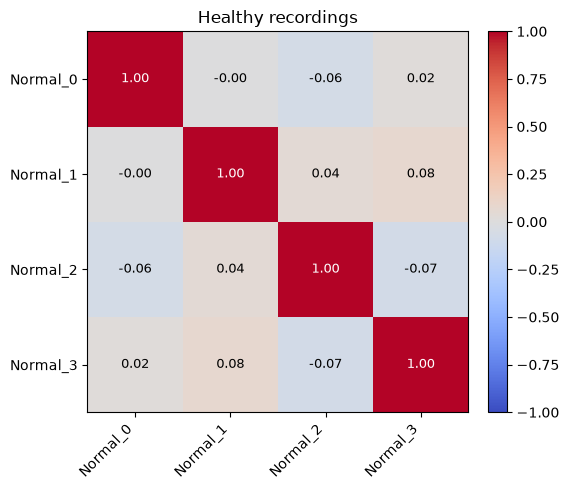

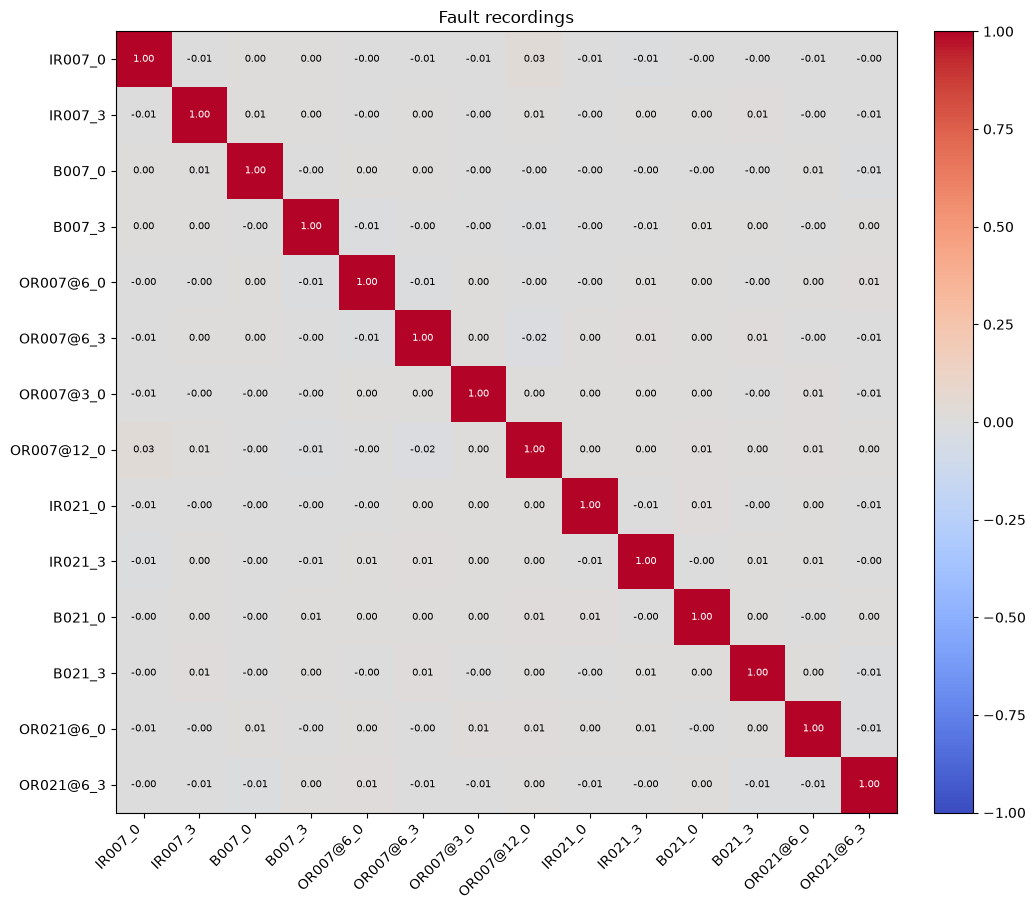

In [7]:
def at_12khz(row):
    samples = np.asarray(row["drive"], dtype=np.float64)
    if int(row["fs"]) == FS:
        return samples
    target = int(np.round(samples.size * FS / row["fs"]))
    return resample(samples, target)


def recording_matrix(group):
    traces = [at_12khz(row) for row in group]
    common = min(trace.size for trace in traces)
    stack = np.stack([trace[:common] for trace in traces])
    return np.corrcoef(stack), common


def draw_matrix(matrix, names, title):
    figure, axis = plt.subplots(figsize=(max(6, 0.62 * len(names) + 2), max(5, 0.55 * len(names) + 1.5)))
    image = axis.imshow(matrix, vmin=-1, vmax=1, cmap="coolwarm")
    axis.set_xticks(range(len(names)), names, rotation=45, ha="right")
    axis.set_yticks(range(len(names)), names)
    axis.set_title(title)
    for row_index in range(len(names)):
        for col_index in range(len(names)):
            value = matrix[row_index, col_index]
            axis.text(
                col_index,
                row_index,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=7 if len(names) > 6 else 9,
                color="white" if abs(value) > 0.55 else "black",
            )
    figure.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
    figure.tight_layout()


healthy_rows = [row for row in rows if row["fault"] == "normal"]
fault_rows = [row for row in rows if row["fault"] != "normal"]
healthy_corr, healthy_n = recording_matrix(healthy_rows)
fault_corr, fault_n = recording_matrix(fault_rows)


def off_diagonal(matrix):
    return matrix[np.triu_indices(matrix.shape[0], k=1)]


healthy_off = off_diagonal(healthy_corr)
fault_off = off_diagonal(fault_corr)
print(f"Healthy, {healthy_n / FS:.2f} s in common. Off-diagonal {healthy_off.min():+.2f} to {healthy_off.max():+.2f}.")
print(f"Fault, {fault_n / FS:.2f} s in common. Off-diagonal {fault_off.min():+.2f} to {fault_off.max():+.2f}.")

draw_matrix(healthy_corr, [row["name"] for row in healthy_rows], "Healthy recordings")
draw_matrix(fault_corr, [row["name"] for row in fault_rows], "Fault recordings")
plt.show()
